# **실습 개요**

여러분은 대형마트 **데이터분석팀**에 합류한 데이터 분석가입니다.<br>
마케팅팀에서 "장바구니에 어떤 상품들이 자주 함께 담기는지 알아내서, 매대 배치와 묶음 프로모션에 활용하고 싶다"는 요청을 받았습니다.

이 데이터를 정제한 뒤, **연관 규칙 학습(Association Rule Learning)** 의 대표 알고리즘인 **Apriori**를 이용해 <br>
"이 상품을 사면 저 상품도 함께 산다"는 규칙을 찾아내고, 이를 활용해 **장바구니 추천**까지 만들어봅시다.

## **데이터셋 설명**

| 컬럼명 | 설명 |
|---|---|
| transaction_id | 거래 고유 ID |
| date | 거래 일시 |
| store_branch | 매장 지점 (강남점/홍대점/잠실점/분당점) |
| customer_type | 고객 등급 (신규/기존/VIP) |
| payment_method | 결제 수단 (카드/현금/모바일페이) |
| num_items | 장바구니에 담긴 상품 개수 |
| total_amount | 총 결제 금액 (원) |
| items | 장바구니에 담긴 상품 목록 (쉼표로 구분된 문자열) |

## **데이터셋 URL**
URL : https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/mart_transactions.csv


## **한글 폰트 설치하기**

In [1]:
# 한글 설치
!pip install -q koreanize-matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import koreanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 60.4 MB/s eta 0:00:00


## **Warning 안뜨게 하기**

In [27]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.


**Q1. mart_transactions.csv 파일을 읽어온 뒤 첫 5개의 행을 출력하세요.**

In [28]:
df = pd.read_csv('https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/mart_transactions.csv')
df.head()

,transaction_id,date,store_branch,customer_type,payment_method,num_items,total_amount,items
0,11179,2026-05-07 18:38,분당점,기존,현금,7,38600.0,"소고기,계란,감자칩,콜라,라면,커피,크루아상"
1,10866,2026-05-04 15:25,강남점,신규,카드,5,9800.0,"감자칩,콜라,마늘,양파,크루아상"
2,10102,2026-04-07 12:25,분당점,기존,모바일페이,4,12000.0,"요거트,콜라,맥주,감자칩"
3,10440,2026-03-07 21:05,홍대점,신규,현금,9,64300.0,"소고기,계란,맥주,시리얼,감자칩,콜라,기저귀,라면,커피"
4,10059,2026-04-28 08:19,강남점,신규,모바일페이,1,19400.0,소고기


**Q2. 데이터의 전반적인 정보를 확인하세요.**

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  1200 non-null   int64  
 1   date            1200 non-null   object 
 2   store_branch    1200 non-null   object 
 3   customer_type   1200 non-null   object 
 4   payment_method  1200 non-null   object 
 5   num_items       1200 non-null   int64  
 6   total_amount    1200 non-null   float64
 7   items           1200 non-null   object 
dtypes: float64(1), int64(2), object(5)
memory usage: 75.1+ KB


**Q3. 수치형 컬럼의 기초 통계량을 확인하세요.**

In [30]:
df.describe()

,transaction_id,num_items,total_amount
count,1200.000000,1200.000000,1200.000000
mean,10600.500000,4.042500,20742.083333
std,346.554469,2.310875,13555.917764
min,10001.000000,1.000000,1000.000000
25%,10300.750000,2.000000,9600.000000
50%,10600.500000,4.000000,19200.000000
75%,10900.250000,6.000000,29325.000000
max,11200.000000,12.000000,68500.000000


## **2. 데이터 분석하기**


**Q1. 장바구니에 담긴 상품 개수가 가장 많은 상위 5개 거래의 품목을 확인하세요.**

In [31]:
df.nlargest(5, 'num_items')['items']

,items
52,"삼겹살,라면,상추,식빵,버터,맥주,커피,크루아상,양파,마늘,우유,계란"
217,"식빵,바나나,우유,시리얼,감자칩,버터,콜라,파스타소스,화장지,커피,양파,크루아상"
787,"마늘,라면,버터,세제,닭가슴살,크루아상,우유,커피,계란,식빵,감자칩,삼겹살"
846,"파스타,계란,맥주,식빵,우유,시리얼,감자칩,삼겹살,파스타소스,콜라,기저귀,라면"
1100,"커피,우유,식빵,파스타,계란,맥주,감자,버터,콜라,파스타소스,상추,기저귀"


**Q2. 가장 많이 등장한 상품 2개 조합 TOP5를 찾아 출력해주세요.**

- itertools.combinations(리스트, 2) : 리스트 내의 항목들을 2개씩 묶어 리스트로 반환한다.

```
from itertools import combinations
for combo in combinations(sorted(item_list), 2):
   print(combo)
```

In [32]:
from itertools import combinations

counter = {}
for items in df['items']:
  item_list = items.split(',')
  for combo in combinations(sorted(item_list), 2):
    if combo in counter:
      counter[combo] += 1
    else:
      counter[combo] = 1

counter = sorted(counter.items(), key=lambda x: x[1], reverse=True)
counter[:5]

[(('기저귀', '맥주'), 203),
 (('파스타', '파스타소스'), 190),
 (('감자칩', '콜라'), 187),
 (('시리얼', '우유'), 179),
 (('식빵', '우유'), 162)]

**Q3. 전체 거래에서 가장 많이 팔린 상품 TOP 15를 막대그래프로 그리세요.**

In [33]:
items = df['items'].str.split(',').explode()

In [34]:
top15 = items.value_counts().sort_values(ascending=False)[:15]

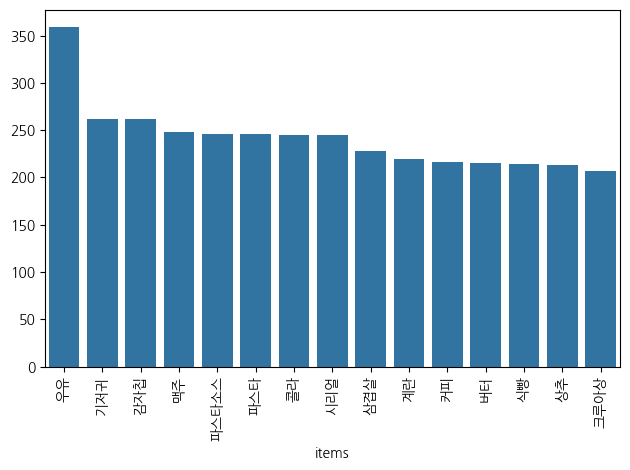

In [35]:
# barplot의 간격을 늘림
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(x=top15.index, y=top15.values)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## **3. 데이터 전처리하기**


### **3-3. 인코딩**

**Q. items컬럼을 Apriori가 사용할 수 있는 형태로 변환하세요.**

- Transaction Encoder를 사용해 각 거래를 상품별 True/False로 이루어진 원-핫 인코딩 행렬로 바꾸세요.

```
mlxtend.preprocessing.TransactionEncoder
```

In [36]:
transactions = df['items'].str.split(',')
transactions.head()

,items
0,"[소고기, 계란, 감자칩, 콜라, 라면, 커피, 크루아상]"
1,"[감자칩, 콜라, 마늘, 양파, 크루아상]"
2,"[요거트, 콜라, 맥주, 감자칩]"
3,"[소고기, 계란, 맥주, 시리얼, 감자칩, 콜라, 기저귀, 라면, 커피]"
4,[소고기]


In [37]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
transactions_encoded = te.fit_transform(transactions)

In [38]:
df_encoded = pd.DataFrame(transactions_encoded, columns=te.columns_)

In [39]:
df_encoded.head()

,감자,감자칩,계란,기저귀,닭가슴살,라면,마늘,맥주,바나나,버터,...,요거트,우유,초콜릿,치즈,커피,콜라,크루아상,파스타,파스타소스,화장지
0,False,True,True,False,False,True,False,False,False,False,...,False,False,False,False,True,True,True,False,False,False
1,False,True,False,False,False,False,True,False,False,False,...,False,False,False,False,False,True,True,False,False,False
2,False,True,False,False,False,False,False,True,False,False,...,True,False,False,False,False,True,False,False,False,False
3,False,True,True,True,False,True,False,True,False,False,...,False,False,False,False,True,True,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## **4. 모델링**
- mlxtend라이브러리의 apriori와 association_rules를 이용해 frequent itemset과 연관 규칙을 찾습니다.


Deprecation Warning이 많이 뜰겁니다.
- 이를 방지하기 위해 아래에서 Warning을 무시하는 코드를 꼭 실행시켜 주세요.

In [40]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

### **4-1 빈발 아이템셋(Frequent Itemsets)탐색**

**Q1. 최소 지지도를 만족하는 빈발 아이템셋을 찾으세요.**
- min_support = 0.03

```
mlxtend.frequent_patters.apriori
```

In [41]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(df_encoded, min_support=0.03, use_colnames=True)

In [42]:
frequent_itemsets

,support,itemsets
0,0.056667,(감자)
1,0.218333,(감자칩)
2,0.182500,(계란)
3,0.218333,(기저귀)
4,0.052500,(닭가슴살)
...,...,...
188,0.032500,"(파스타소스, 파스타, 커피)"
189,0.033333,"(콜라, 파스타, 파스타소스)"
190,0.030833,"(파스타소스, 파스타, 크루아상)"
191,0.030000,"(맥주, 우유, 기저귀, 시리얼)"


**Q2. 빈발 아이템셋을 정렬해서 top10만 출력합니다.**

In [43]:
frequent_itemsets = frequent_itemsets.sort_values('support', ascending=False)

In [44]:
frequent_itemsets.head(10)

,support,itemsets
20,0.299167,(우유)
3,0.218333,(기저귀)
1,0.218333,(감자칩)
7,0.206667,(맥주)
26,0.205000,(파스타)
27,0.205000,(파스타소스)
24,0.204167,(콜라)
16,0.204167,(시리얼)
11,0.190000,(삼겹살)
2,0.182500,(계란)


### **4.2 연관 규칙(Association Rules) 생성**

**Q1. association_rules를 이용해 confidence >= 0.6인 연관 규칙을 생성하세요.**

```
from mlxtend.frequent_patterns import association_rules
```

In [45]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)
rules[['antecedents', 'support', 'confidence', 'lift', 'consequents']]

,antecedents,support,confidence,lift,consequents
0,(맥주),0.169167,0.818548,3.749077,(기저귀)
1,(기저귀),0.169167,0.774809,3.749077,(맥주)
2,(파스타소스),0.158333,0.772358,3.767599,(파스타)
3,(파스타),0.158333,0.772358,3.767599,(파스타소스)
4,(콜라),0.155833,0.763265,3.495872,(감자칩)
...,...,...,...,...,...
115,"(맥주, 우유, 기저귀)",0.030000,0.600000,2.938776,(시리얼)
116,"(맥주, 우유, 시리얼)",0.030000,0.923077,4.227833,(기저귀)
117,"(맥주, 기저귀, 시리얼)",0.030000,0.734694,2.455801,(우유)
118,"(우유, 기저귀, 시리얼)",0.030000,0.818182,3.958944,(맥주)


**Q. 생성된 규칙을 lift기준 내림차순으로 정렬하여 상위 10개를 확인합니다.**

- 가장 lift가 높은 규칙 1개를 해석해보세요.

In [46]:
top_rules = rules.sort_values('lift', ascending=False).head(10)
top_rules[['antecedents', 'support', 'confidence', 'lift', 'consequents']]

,antecedents,support,confidence,lift,consequents
119,"(맥주, 시리얼)",0.030000,0.679245,10.317650,"(우유, 기저귀)"
62,"(우유, 상추)",0.035000,0.763636,5.989305,"(마늘, 삼겹살)"
61,"(우유, 마늘)",0.035000,0.711864,5.694915,"(삼겹살, 상추)"
58,"(우유, 삼겹살, 상추)",0.035000,0.976744,5.662285,(마늘)
26,"(삼겹살, 상추)",0.121667,0.973333,5.642512,(마늘)
27,(마늘),0.121667,0.705314,5.642512,"(삼겹살, 상추)"
29,(상추),0.121667,0.685446,5.376047,"(마늘, 삼겹살)"
24,"(마늘, 삼겹살)",0.121667,0.954248,5.376047,(상추)
19,(식빵),0.125000,0.700935,5.357462,"(우유, 버터)"
15,"(우유, 버터)",0.125000,0.955414,5.357462,(식빵)


**Q3. 기저귀가 antecedents(선행 상품)에 포함된 규칙만 필터링해서 확인하세요.**

In [47]:
diaper_rules = rules[['기저귀' in r for r in rules['antecedents']]]

In [48]:
diaper_rules = diaper_rules.sort_values('lift', ascending=False)

In [49]:
diaper_rules[['antecedents', 'support', 'confidence', 'lift', 'consequents']]

,antecedents,support,confidence,lift,consequents
52,"(기저귀, 파스타)",0.036667,0.846154,4.094293,(맥주)
77,"(파스타소스, 기저귀)",0.033333,0.816327,3.982081,(파스타)
118,"(우유, 기저귀, 시리얼)",0.030000,0.818182,3.958944,(맥주)
74,"(파스타소스, 기저귀)",0.033333,0.816327,3.949967,(맥주)
99,"(기저귀, 상추)",0.030833,0.804348,3.892006,(맥주)
41,"(기저귀, 시리얼)",0.040833,0.803279,3.886832,(맥주)
68,"(계란, 기저귀)",0.034167,0.788462,3.815136,(맥주)
43,"(콜라, 기저귀)",0.038333,0.779661,3.772553,(맥주)
78,"(기저귀, 파스타)",0.033333,0.769231,3.752345,(파스타소스)
1,(기저귀),0.169167,0.774809,3.749077,(맥주)


## **5. 추천 시스템**

- 사용자가 장바구니에 넣은 상품들을 기반으로, 품목들을 추천해보는 프로그램을 작성해 봅시다.

In [50]:
def recommend(basket):
  # antecedents를 포함하는 규칙만 선택
  matched = rules[[all(item in basket for item in r) for r in rules['antecedents']]]
  if matched.empty:
    return []

  # 이미 basket에 있는 상품은 추천에서 제외한다.
  pool = matched[[all(item not in basket for item in r) for r in matched['consequents']]]
  if pool.empty:
    return []

  recommendations = {}
  for _, row in pool.iterrows():
    for item in row['consequents']:
      confidence = row['confidence']
      lift = row['lift']
      recommendations[item] = {'confidence': confidence, 'lift': lift}

  top5 = sorted(recommendations.items(), key=lambda x: x[1]['lift'], reverse=True)[:5]
  return [(item[0], item[1]) for item in top5]

In [51]:
recommend(['기저귀','라면','맥주','삼겹살','상추','시리얼','양파','우유'])

[('계란', {'confidence': 0.8181818181818181, 'lift': 4.483188044831881}),
 ('마늘', {'confidence': 0.72, 'lift': 4.173913043478261})]